In [1]:
print ("Hello Iris!")

Hello Iris!


## Phase 2: Python Fundamentals

In [2]:
# Variables
# Storing metadata about the Iris dataset

n_rows = 150               # total instances in the dataset
n_classes = 3              # number of species
n_per_class = 50           # number of flowers in each of the classes
n_attributes = 4           # numeric measurements 

# 
print("Rows:", n_rows)
print("Number of Species:", n_rows / n_per_class)


Rows: 150
Number of Species: 3.0


In [3]:
# Control structures 
# Check petal and sepal length and label

petal_length = 1.0
sepal_length = 6.3


if petal_length > 1.5:
    print("Large petal")
else: 
    print("Small petal")
if sepal_length > 5.0:
    print("Large sepal")
else: 
    print("Small sepal")


Small petal
Large sepal


In [4]:
# Loops
# List the three species in the dataset

species_list = ['Iris setosa', 'Iris versicolour', 'Iris virginica']

for species in species_list:
    print(species)


Iris setosa
Iris versicolour
Iris virginica


In [5]:
# Functions
# Classify and label flowers 

def classify_flower(sepal_length, petal_length):
    if petal_length < 2.5 and sepal_length < 5.4:
        return "Small size flower"
    elif petal_length >= 5.0 and sepal_length >= 6.0:
        return "Large size flower"
    else:
        return "Medium size flower"

print(classify_flower(6.2,7.0,))
print(classify_flower(1.2,1.0,))
print(classify_flower(4.0,7.0,))

Large size flower
Small size flower
Medium size flower


In [6]:
import os 
print(os.listdir())

['iris.names', 'iris_project.ipynb', 'iris_cleaned.csv', 'iris.csv', 'summary.txt', '.ipynb_checkpoints', 'iris_classes.csv']


## Phase 3: File Handling and Data Cleaning 

In [7]:
import csv 

rows = []
with open("iris.csv", "r") as f:           # 'r' in second argument to read file
    reader = csv.reader(f)
    for row in reader:
        if len(row) > 0:                   # the file includes empty lines, so we need to skip
            rows.append(row)

print(rows[4])

['5.0', '3.6', '1.4', '0.2', 'Iris-setosa']


In [8]:
# Get the statistics 

sepal_length = []                               # min, max, and average values
sepal_width = []
petal_length = []
petal_width = []

for row in rows:
    sepal_length.append(float(row[0]))
    sepal_width.append(float(row[1]))
    petal_length.append(float(row[2]))
    petal_width.append(float(row[3]))

columns = {
    "sepal_length": sepal_length,
    "sepal_width": sepal_width,
    "petal_length": petal_length,
    "petal_width": petal_width
}

with open("summary.txt", "w") as f:               # write the summary of the values. 'w' in the second argument writes a new file. 
    f.write("Iris Dataset Summary\n")
    f.write(f"Row count: {len(rows)}\n")
    for name in columns:
        values = columns[name]
        average = round(sum(values) / len(values), 2)
        f.write(f"{name} - min: {min(values)}, max: {max(values)}, average: {average}\n")

 
with open("summary.txt", "r") as f:                # check if summary text worked 
    print(f.read())

Iris Dataset Summary
Row count: 150
sepal_length - min: 4.3, max: 7.9, average: 5.84
sepal_width - min: 2.0, max: 4.4, average: 3.05
petal_length - min: 1.0, max: 6.9, average: 3.76
petal_width - min: 0.1, max: 2.5, average: 1.2



In [9]:
import pandas as pd

# The file has no headers for values, so we name our columns 

df = pd.read_csv("iris.csv", header = None,
                 names=["sepal_length", "sepal_width", "petal_length", "petal_width", "species"])

print(df.shape)    # should be (150, 5)
df.head()

(150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [10]:
#check for missing values, column names and data types

print("Column names:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

df.describe() 

Column names:
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

Data types:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [11]:
df = df.dropna()
df["species"] = df["species"].str.strip()

print(df.shape)   # is still (150, 5) if the data was already clean

# index=False stops pandas from adding an extra column of row numbers
df.to_csv("iris_cleaned.csv", index=False)

(150, 5)


The dataset has 150 rows and 5 columns. The four measurement columns are floats and class is text. There are no missing values, so no rows need to be dropped.

In [12]:
check = pd.read_csv("iris_cleaned.csv")
print(check.shape)
check.head()

(150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## Phase 4: Analysis & Visualization 

In [13]:
import pandas as pd
import matplotlib.pyplot as plt 


df = pd.read_csv("iris_cleaned.csv")

# Count flowers of each species through a for loop 
species_count = {} 

for species in df['species']:
    if species in species_count:
        species_count[species] += 1
    else: 
        species_count[species] = 1

print("Number of Flower of each Species: ", species_count)

df["species"].value_counts()

Number of Flower of each Species:  {'Iris-setosa': 50, 'Iris-versicolor': 50, 'Iris-virginica': 50}


species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [14]:
# Categorize flowers by petal length 

categorize_petal = []
for petal_length in df['petal_length']:
    if petal_length < 2:
        categorize_petal.append("Short Petal")
    elif petal_length >= 2 and petal_length <= 5:
        categorize_petal.append("Medium Petal")
    else:
        petal_length > 5 
        categorize_petal.append("Long Petal")

df['petal_category'] = categorize_petal

# Save updated categorized flowers into csv_file 
df.to_csv('iris_classes.csv')   

print(df[['petal_length', 'petal_category']].head(5))

   petal_length petal_category
0           1.4    Short Petal
1           1.4    Short Petal
2           1.3    Short Petal
3           1.5    Short Petal
4           1.4    Short Petal


Pandas Analysis

In [15]:
# Calculate mean, median, min, max of sepal and petal lenghts

df[['sepal_length', 'petal_length']].agg(['mean', 'median', 'min', 'max'])

,sepal_length,petal_length
mean,5.843333,3.758667
median,5.800000,4.350000
min,4.300000,1.000000
max,7.900000,6.900000


In [16]:
# Compute averages and group by sepal and petal lengths

df.groupby("species")[['sepal_length', 'petal_length']].mean()

,sepal_length,petal_length
species,,
Iris-setosa,5.006,1.464
Iris-versicolor,5.936,4.260
Iris-virginica,6.588,5.552


Visualizations (matplotlip & pandas)

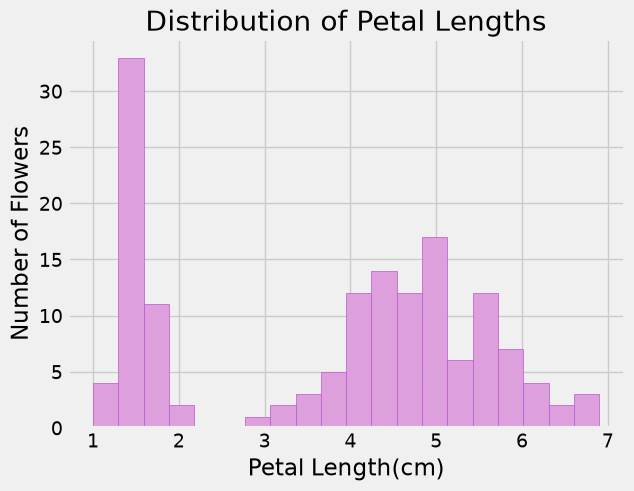

In [17]:
# Histogram of petal length 

plt.style.use('fivethirtyeight') 

plt.hist(df["petal_length"], bins=20, color='plum', edgecolor='mediumorchid')
plt.xlabel('Petal Length(cm)')
plt.ylabel('Number of Flowers')
plt.title('Distribution of Petal Lengths')
plt.show()

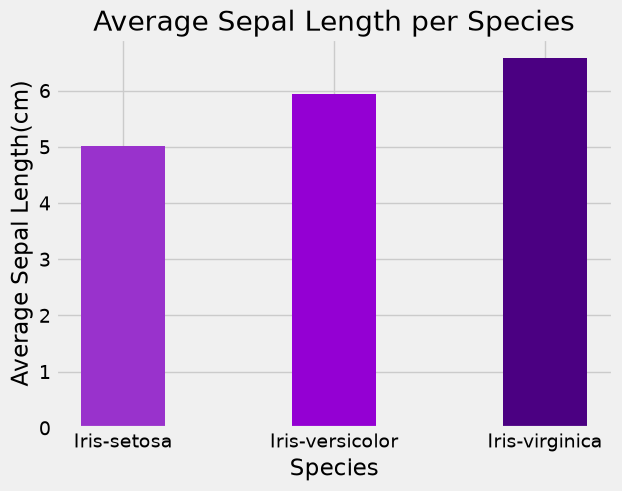

In [18]:
# Bar chart of average sepal length per species  

plt.style.use('fivethirtyeight') 
avg = df.groupby('species')['sepal_length'].mean()

plt.bar(avg.index, avg.values, width = 0.4, color=[ 'darkorchid','darkviolet', 'indigo'])
plt.xlabel('Species')
plt.ylabel('Average Sepal Length(cm)')
plt.title('Average Sepal Length per Species')
plt.show()

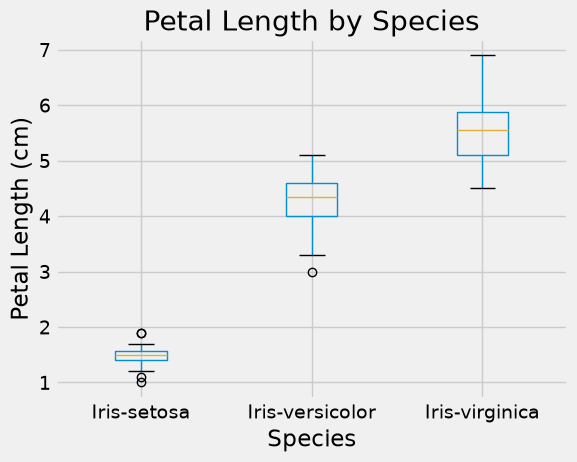

In [19]:
# Boxplot of petal length per species 

plt.style.use('fivethirtyeight') 
df.boxplot(column="petal_length", by="species", grid=True)         
plt.ylabel("Petal Length (cm)")
plt.title("Petal Length by Species")

# removes pandas' automatic extra title
plt.xlabel("Species")
plt.suptitle("") 

plt.show()

Discussion questions:
1. Which species has the smallest range of petal length?

Iris setosa has the smallest range. Its petal lengths run from 1.0cm to 1.9cm, a range of 0.9cm. The other two species have larger ranges; Iris versicolor has a range of 2.1 cm, and Iris virginica has 2.4 cm. 

2. Which species shows the largest spread in petal length values?  

Iris virginica has the largest spread. Its petal length runs from 4.5 cm to 6.9 cm, a range of 2.4 cm. 

3. How do the medians of the three species compare? What does this suggest about their flower size?

Median Values:  Iris-setosa	1.50, Iris-versicolor 4.35, and Iris-virginica 5.55
The median values between Iris setosa and the other species are large, meaning they are identifiable by their petal length. The median values of Iris versicolor and Iris virginica are not as large and have overlapping values. This makes it hard to differentiate versicolor and virginica only based on size. 

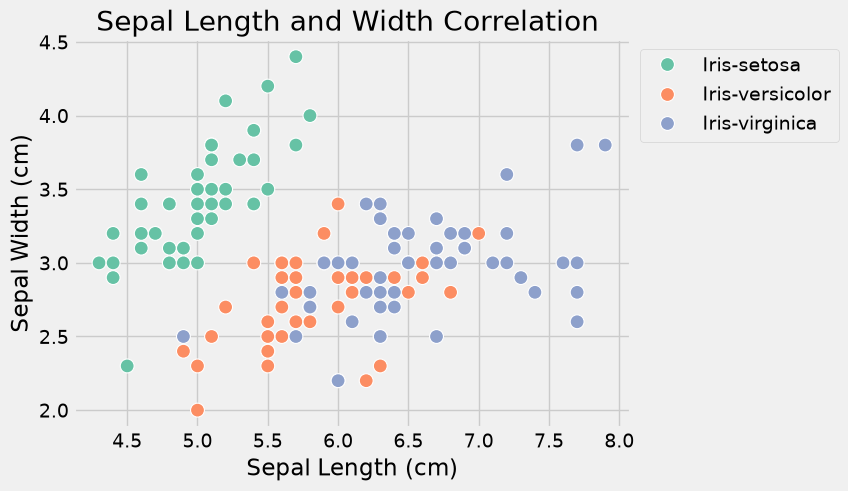

In [20]:
# Scatterplot of correlation  of sepal lenght and width 

import seaborn as sns

sns.scatterplot(x='sepal_length', y='sepal_width', hue='species', data=df, palette='Set2',s=100 )


plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('Sepal Length and Width Correlation ')

# Placing Legend outside the Figure
plt.legend(bbox_to_anchor=(1, 1), loc=2)

plt.show()


Discussion questions:
1. Do sepal length and sepal width appear strongly correlated? Explain why or why not using evidence from the scatter plot. 

No, sepal length and sepal width are not strongly correlated. The scatterplot shows no clear linear trend. Iris setosa has wider petals and shorter petals, while versicolor and virginica spread out with longer petals and moderate width. 

2. Based on the scatter plot, boxplot, and histogram, which flower features(sepal length, sepal width, petal length, petal width) seem most useful for separating the species?
   
The most useful features are petal length and width. The boxplot for petal length shows each species in separate bands, similar for their width as well, with small overlap between versicolor and virginica. Sepal length and width don't show much differentiation, as seen with the scatter plot seratosa is separated completely, and versicolor and virginica have minor overlap. 